# P1: Factors Affecting Final Grades (student-mat)

**Main question:** How do studytime, absences, family support and intermediate grades (G1/G2) relate to the final grade (G3)?

- Data: UCI Student Performance (`student-mat.csv` primary, `student-por.csv` for comparison) + Wikipedia PISA reference
- Pipeline: `StudentDataProcessor.load_data → clean_data → analyze → export_results` (`data_processor.py`, run via `main.py`)
- Outputs: `data/processed/cleaned_students.csv`, `pisa_clean.csv`, `summary.json`, 3 required charts + 1 PISA chart in `images/`

## 1. Python basics: 4 functions + data structures

`convert_yes_no`, `calc_pass_fail`, `classify_absences`, `calc_average_grade`; `list[dict]` sample students, `dict` mapping, `set()` uniques, `tuple` thresholds.

In [1]:
from data_processor import (
    THRESHOLDS, ANOMALY_THRESHOLDS, VAR_DESCRIPTIONS, SAMPLE_STUDENTS,
    convert_yes_no, calc_pass_fail, classify_absences, calc_average_grade,
)

print('THRESHOLDS (PASS, G_WARN, ABS_MED, ABS_HIGH, FAIL_HIGH):', THRESHOLDS)
print('ANOMALY_THRESHOLDS (IQR_K, G1_DROP, G2_DROP, AGE_OUTLIER):', ANOMALY_THRESHOLDS)
print('famsup =', VAR_DESCRIPTIONS['famsup'])
print('convert_yes_no:', convert_yes_no(' Yes '), convert_yes_no('no'), convert_yes_no('maybe'))
for s in SAMPLE_STUDENTS:
    print(s['id'], calc_pass_fail(s['G3']), classify_absences(s['absences']),
          round(calc_average_grade(s['G1'], s['G2'], s['G3']), 2), convert_yes_no(s['internet']))

THRESHOLDS (PASS, G_WARN, ABS_MED, ABS_HIGH, FAIL_HIGH): (10, 10, 4, 10, 2)
ANOMALY_THRESHOLDS (IQR_K, G1_DROP, G2_DROP, AGE_OUTLIER): (1.5, 8, 6, 20)
famsup = Family educational support (yes/no)
convert_yes_no: 1 0 None
1 fail medium 5.67 1
2 fail medium 5.33 0
3 pass high 8.33 1


## 2. Collect + load (UCI zip, PISA scrape)

In [2]:
from pathlib import Path
from data_processor import StudentDataProcessor, fetch_uci_raw, scrape_pisa_table

RAW = Path('data/raw')
fetch_uci_raw(RAW)
pisa_raw = scrape_pisa_table(out_csv=RAW / 'pisa_reference.csv')
print('PISA raw rows:', len(pisa_raw))

proc = StudentDataProcessor({'mat': RAW / 'student-mat.csv', 'por': RAW / 'student-por.csv'},
                            RAW / 'pisa_reference.csv', Path('data/processed'), Path('images'),
                            oecd_raw=RAW / 'oecd_pisa2025_table_I1.csv')
df = proc.load_data()
print(df.shape, df['subject'].value_counts().to_dict())

PISA raw rows: 2342
(1044, 34) {'por': 649, 'mat': 395}


## 3. Clean: validation log + anomaly flags (flag, never delete)

In [3]:
import json
clean = proc.clean_data()
log = proc.cleaning_log
print({k: v for k, v in log.items() if isinstance(v, int)})
print('out-of-range total:', sum(log['n_out_of_range'].values()),
      '| invalid yes/no total:', sum(log['n_invalid_yes_no'].values()))
print('absence outlier fence per subject:', log['absence_outlier_fence'])

from data_processor import FLAG_COLS
print(clean.groupby('subject')[FLAG_COLS].sum().T)

{'rows_in': 1044, 'n_cells_stripped': 0, 'n_duplicates_dropped': 0, 'n_missing_required_dropped': 0, 'rows_out': 1044}
out-of-range total: 0 | invalid yes/no total: 0
absence outlier fence per subject: {'mat': 20.0, 'por': 15.0}
subject             mat  por
dropout_suspect      38   15
g2_zero              13    7
grade_drop            0    1
absence_outlier      15   21
age_outlier           5    9
inconsistent_grade    0    0


G3 = 0 students: 38 | with absences == 0: 38 | with G2 == 0: 13
             G1         G2   G3  absences  failures
mean   7.526316   4.657895  0.0       0.0  0.921053
min    4.000000   0.000000  0.0       0.0  0.000000
max   12.000000  10.000000  0.0       0.0  3.000000


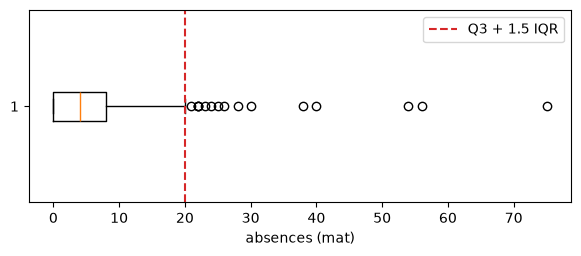

In [4]:
mat = clean[clean['subject'] == 'mat']
zero = mat[mat['dropout_suspect']]
print('G3 = 0 students:', len(zero), '| with absences == 0:', int((zero['absences'] == 0).sum()),
      '| with G2 == 0:', int((zero['G2'] == 0).sum()))
print(zero[['G1', 'G2', 'G3', 'absences', 'failures']].describe().loc[['mean', 'min', 'max']])

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.boxplot(mat['absences'], orientation='horizontal')
ax.axvline(log['absence_outlier_fence']['mat'], color='C3', ls='--', label='Q3 + 1.5 IQR')
ax.set_xlabel('absences (mat)'); ax.legend(); plt.show()

## 4. EDA: groupby mean/std (all vs exclude_dropout)

In [5]:
res = proc.analyze()
for scope in ['all', 'exclude_dropout']:
    s = res['scopes'][scope]
    print(f"\n### {scope}: n={s['n']} pass_rate={s['pass_rate']} (pass {s['n_pass']} / fail {s['n_fail']})")
    for key in ['by_studytime', 'by_absence_level', 'by_failures', 'by_internet',
                'by_famsup', 'by_schoolsup', 'by_paid', 'by_risk_group']:
        print(f"  {key}: " + ', '.join(f"{g}={v['mean']}±{v['std']} (n={v['n']})" for g, v in s[key].items()))


### all: n=395 pass_rate=0.6709 (pass 265 / fail 130)
  by_studytime: 1=10.05±4.96 (n=105), 2=10.17±4.22 (n=198), 3=11.4±4.64 (n=65), 4=11.26±5.28 (n=27)
  by_absence_level: high=10.37±3.2 (n=83), low=9.82±5.61 (n=191), medium=11.38±3.25 (n=121)
  by_failures: 0=11.25±4.17 (n=312), 1=8.12±4.71 (n=50), 2=6.24±4.84 (n=17), 3=5.69±4.19 (n=16)
  by_internet: no=9.41±4.49 (n=66), yes=10.62±4.58 (n=329)
  by_famsup: no=10.64±4.64 (n=153), yes=10.27±4.55 (n=242)
  by_schoolsup: no=10.56±4.77 (n=344), yes=9.43±2.87 (n=51)
  by_paid: no=9.99±5.13 (n=214), yes=10.92±3.79 (n=181)
  by_risk_group: high=6.22±3.85 (n=149), low=13.57±2.51 (n=169), medium=11.6±2.83 (n=77)

### exclude_dropout: n=357 pass_rate=0.7423 (pass 265 / fail 92)
  by_studytime: 1=11.47±3.41 (n=92), 2=11.07±3.07 (n=182), 3=12.56±2.99 (n=59), 4=12.67±3.6 (n=24)
  by_absence_level: high=10.37±3.2 (n=83), low=12.26±3.04 (n=153), medium=11.38±3.25 (n=121)
  by_failures: 0=11.94±3.19 (n=294), 1=10.15±2.6 (n=40), 2=8.83±3.01 (n=12),

## 5. Charts (3 required)

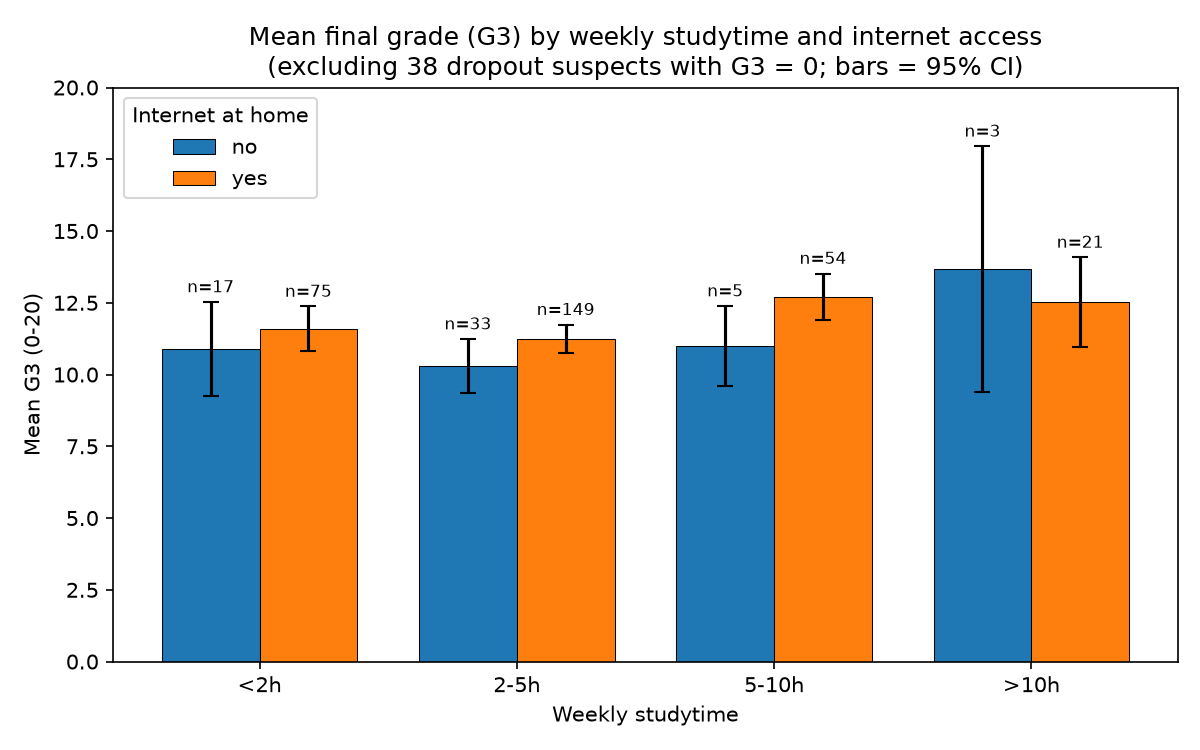

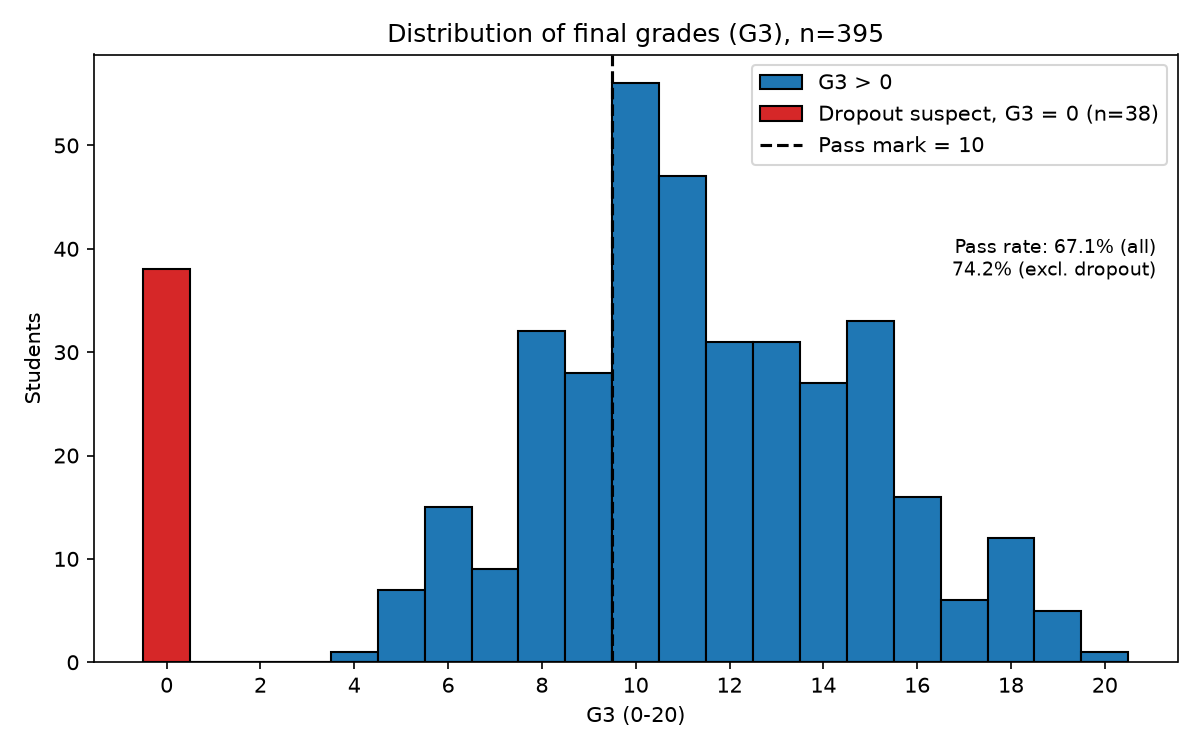

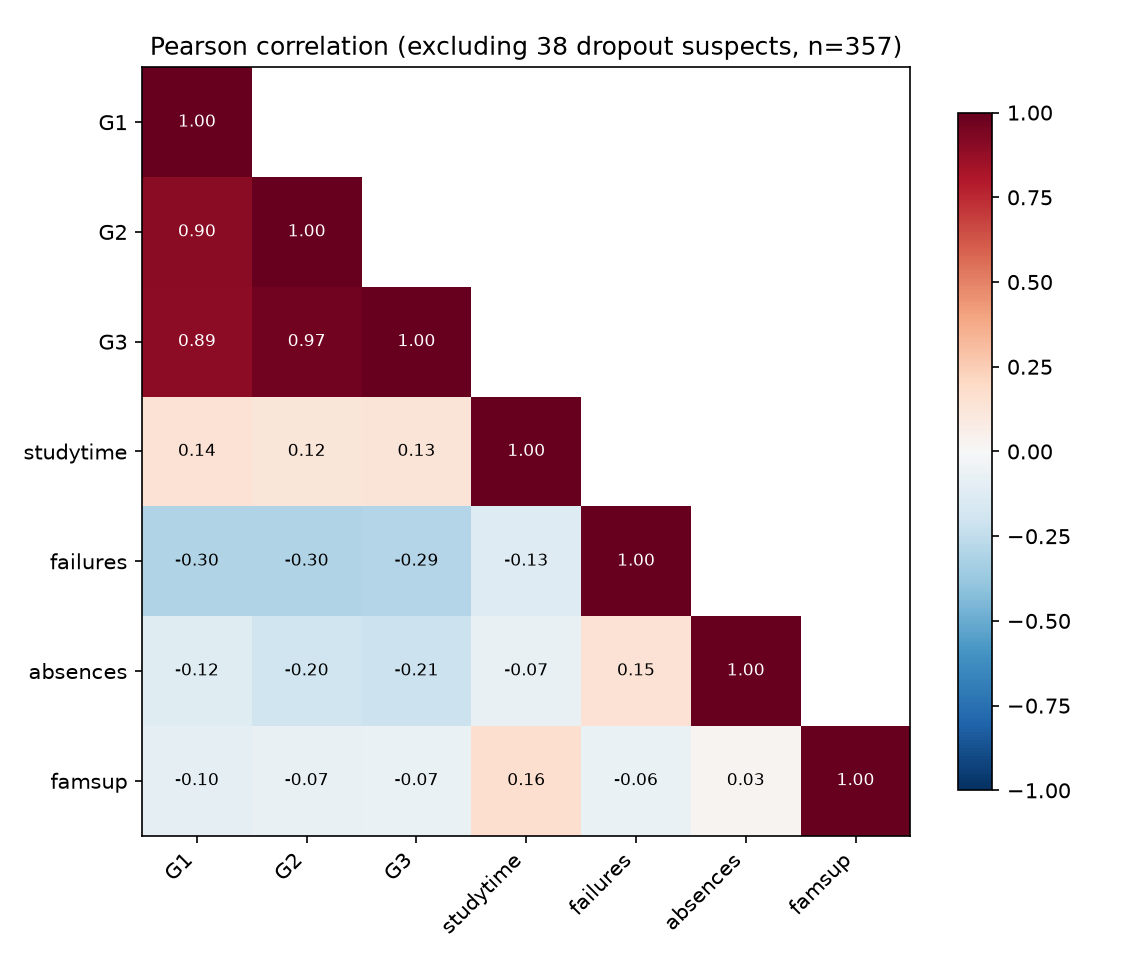

In [6]:
from IPython.display import Image, display
for name in ['01_bar_studytime_internet.png', '02_hist_g3.png', '03_heatmap_corr.png']:
    display(Image(f'images/{name}'))

## 6. Correlation G1/G2/G3 (effect of dropout suspects)

In [7]:
import pandas as pd
for scope in ['all', 'exclude_dropout']:
    print(scope, res['scopes'][scope]['corr_G1_G2_G3'])
print(pd.DataFrame(res['scopes']['exclude_dropout']['corr_full']).round(2).to_string())

all {'G1_G2': 0.852, 'G1_G3': 0.801, 'G2_G3': 0.905}
exclude_dropout {'G1_G2': 0.902, 'G1_G3': 0.892, 'G2_G3': 0.966}
              G1    G2    G3  studytime  failures  absences  famsup_bin
G1          1.00  0.90  0.89       0.14     -0.30     -0.12       -0.10
G2          0.90  1.00  0.97       0.12     -0.30     -0.20       -0.07
G3          0.89  0.97  1.00       0.13     -0.29     -0.21       -0.07
studytime   0.14  0.12  0.13       1.00     -0.13     -0.08        0.16
failures   -0.30 -0.30 -0.29      -0.13      1.00      0.15       -0.06
absences   -0.12 -0.20 -0.21      -0.08      0.15      1.00        0.02
famsup_bin -0.10 -0.07 -0.07       0.16     -0.06      0.02        1.00


## 6b. Significance tests (Welch t / ANOVA + Kruskal-Wallis, Holm-corrected)

In [8]:
tests = pd.DataFrame(res['scopes']['exclude_dropout']['group_tests']).T
print(tests[['test', 'stat', 'p', 'p_holm', 'effect_name', 'effect', 'significant']].to_string())
print()
print(pd.DataFrame(res['scopes']['exclude_dropout']['corr_tests']).T.to_string())

                        test   stat         p    p_holm effect_name effect significant
internet        Welch t-test   2.25    0.0268    0.0804   Cohen's d    0.3       False
famsup          Welch t-test  -1.28     0.202     0.404   Cohen's d  -0.14       False
schoolsup       Welch t-test  -5.46  0.000001  0.000003   Cohen's d  -0.71        True
paid            Welch t-test  -0.55     0.585     0.585   Cohen's d  -0.06       False
studytime      one-way ANOVA   4.38   0.00482    0.0193        eta²  0.036        True
absence_level  one-way ANOVA   9.85  0.000069  0.000343        eta²  0.053        True
failures       one-way ANOVA  11.49       0.0  0.000002        eta²  0.089        True

                r         p              ci95
G1          0.892       0.0    [0.868, 0.911]
G2          0.966       0.0    [0.958, 0.972]
studytime   0.127    0.0166    [0.023, 0.228]
failures   -0.294       0.0  [-0.386, -0.196]
absences   -0.213  0.000049   [-0.31, -0.112]
famsup_bin -0.067     0.205

## 6c. Multivariable regression (OLS, HC3): effect of each factor with the others held fixed

In [9]:
for subj, models in res['regression'].items():
    for name, m in models.items():
        coef = pd.DataFrame(m['coef']).T[['b', 'ci95', 'p', 'significant']]
        print(f"\n### {subj} / {name}: n={m['n']} R2={m['r2']} adj R2={m['adj_r2']}")
        print(coef.to_string())


### mat / factors: n=357 R2=0.234 adj R2=0.205
                    b              ci95         p significant
intercept      13.007   [7.606, 18.408]  0.000003        True
studytime       0.514    [0.081, 0.948]    0.0202        True
failures       -0.898  [-1.385, -0.411]  0.000334        True
absences       -0.064  [-0.106, -0.023]   0.00262        True
famsup_bin      -0.52   [-1.214, 0.174]     0.142       False
schoolsup_bin  -2.184   [-3.11, -1.258]  0.000005        True
paid_bin       -0.603   [-1.278, 0.071]    0.0793       False
internet_bin    0.527   [-0.367, 1.421]     0.247       False
higher_bin      0.203   [-1.399, 1.805]     0.803       False
Medu            0.267     [-0.1, 0.635]     0.154       False
Fedu            0.186   [-0.194, 0.566]     0.336       False
male            0.402    [-0.255, 1.06]      0.23       False
age             -0.21    [-0.49, 0.071]     0.143       False
urban           0.604   [-0.179, 1.388]      0.13       False

### mat / factors_plu

## 6d. Sensitivity: absences vs G3 under different treatments of the zeros

In [10]:
for subj, scen in res['sensitivity'].items():
    print(subj, 'dropout pattern:', scen['dropout_pattern'])
    print(pd.DataFrame({k: v for k, v in scen.items() if k != 'dropout_pattern'}).T[
        ['n', 'r_absences_G3', 'ci95', 'p', 'mean_G3_by_absence_level', 'anova_p']].to_string())

mat dropout pattern: {'n_dropout': 38, 'n_dropout_absences_zero': 38, 'share_absences_zero_others': 0.2157}
                                     n r_absences_G3             ci95         p                        mean_G3_by_absence_level   anova_p
all                                395         0.034  [-0.065, 0.132]     0.497   {'high': 10.37, 'low': 9.82, 'medium': 11.38}    0.0134
exclude_dropout                    357        -0.213  [-0.31, -0.112]  0.000049  {'high': 10.37, 'low': 12.26, 'medium': 11.38}  0.000069
exclude_dropout_and_zero_absences  280        -0.176  [-0.287, -0.06]   0.00312  {'high': 10.37, 'low': 11.91, 'medium': 11.38}   0.00787
por dropout pattern: {'n_dropout': 15, 'n_dropout_absences_zero': 15, 'share_absences_zero_others': 0.3612}
                                     n r_absences_G3              ci95         p                        mean_G3_by_absence_level   anova_p
all                                649        -0.091  [-0.167, -0.015]    0.0199  {'high': 11

## 7. Risk rule evaluation (no G3 in the rule): in-sample vs holdout (Portuguese)

In [11]:
rows = []
for scope, r in res['risk_eval'].items():
    h = r['high']
    rows.append({'scope': scope, 'n': r['n'], 'fail_rate': r['fail_rate'],
                 'recall': h['recall'], 'recall_ci95': h['recall_ci95'],
                 'precision': h['precision'], 'precision_ci95': h['precision_ci95']})
print(pd.DataFrame(rows).to_string(index=False))
print()
for scope in ['all', 'holdout_por_only']:
    t = res['risk_eval'][scope]['tiers']
    print(scope, {g: f"{t[g]['n_fail']}/{t[g]['n']} = {t[g]['fail_rate']}" for g in ['low', 'medium', 'high']},
          '| medium vs low:', t['medium_vs_low'])

           scope   n  fail_rate  recall      recall_ci95  precision   precision_ci95
             all 395     0.3291  0.9385 [0.8833, 0.9685]     0.8188 [0.7492, 0.8724]
 exclude_dropout 357     0.2577  0.9348 [0.8649, 0.9698]     0.7611 [0.6747, 0.8303]
     holdout_por 649     0.1541  0.9000 [0.8256, 0.9448]     0.5921  [0.5126, 0.667]
holdout_por_only 275     0.2545  0.9143 [0.8253, 0.9601]     0.6598  [0.561, 0.7464]

all {'low': '2/169 = 0.0118', 'medium': '6/77 = 0.0779', 'high': '122/149 = 0.8188'} | medium vs low: {'odds_ratio': 7.06, 'relative_risk': 6.6, 'p': 0.0128, 'significant': True}
holdout_por_only {'low': '1/127 = 0.0079', 'medium': '5/51 = 0.098', 'high': '64/97 = 0.6598'} | medium vs low: {'odds_ratio': 13.7, 'relative_risk': 12.4, 'p': 0.0078, 'significant': True}


## 8. Subject comparison (mat vs por)

In [12]:
print(pd.DataFrame(res['subject_comparison']).T.to_string())

         n  n_dropout_suspect  pass_rate  mean_G3  mean_G3_exclude_dropout  corr_G2_G3_exclude_dropout  corr_absences_G3_exclude_dropout  corr_failures_G3_exclude_dropout
mat  395.0               38.0     0.6709    10.42                    11.52                       0.966                            -0.213                            -0.294
por  649.0               15.0     0.8459    11.91                    12.19                       0.934                            -0.196                            -0.388


## 9. PISA reference (web scraping, country-level context) + cross-check with OECD

(1662, 6) {('comparison', 'mathematics'): array([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022]), ('comparison', 'reading'): array([2000, 2003, 2006, 2009, 2012, 2015, 2018, 2022]), ('comparison', 'science'): array([2006, 2009, 2012, 2015, 2018, 2022]), ('summary', 'mathematics'): array([2025]), ('summary', 'reading'): array([2025]), ('summary', 'science'): array([2025])}
                  portugal  portugal_rank  oecd_average
mathematics 2000       454             23           492
            2003       466             30           499
            2006       466             35           494
            2009       487             31           495
            2012       487             29           494
            2015       492             29           490
            2018       492             28           489
            2022       472             29           472
            2025       460             30           463
reading     2000       470             26           493
        

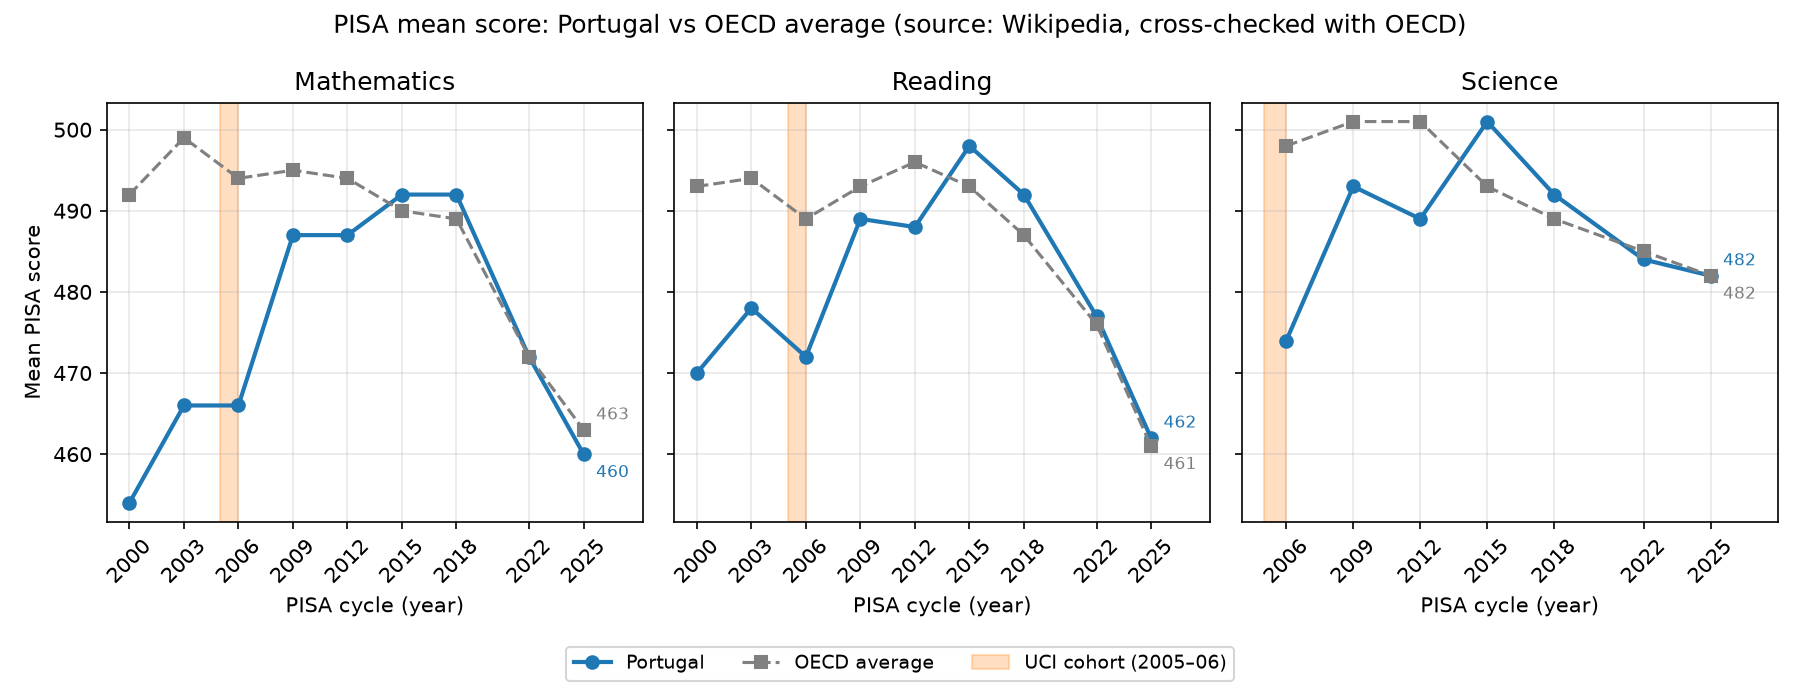

In [13]:
pisa = proc.pisa_clean
print(pisa.shape, pisa.groupby(['source', 'subject'])['year'].unique().to_dict())
ctx = pd.DataFrame({(subj, int(y)): v for subj, years in res['pisa_context'].items()
                    for y, v in years.items()}).T
print(ctx.to_string())
check = res['pisa_oecd_check']
for year in [k for k in check if k.isdigit()]:
    c = check[year]
    print(f"Wikipedia vs OECD {year}: {c['n_within_tolerance']}/{c['n_compared']} within ±{c['tolerance']}, mismatches: {c['mismatches']}")
print('missing in Wikipedia:', check['missing_in_wikipedia'])
display(Image('images/04_pisa_portugal_oecd.png'))

In [14]:
cleaned_csv, summary_json = proc.export_results()
print(cleaned_csv, summary_json)

data\processed\cleaned_students.csv data\processed\summary.json


## 10. Insights + limitations

Generated from `res` by `report_builder.py` (same text as `report.md` sections 1 and 13), so the numbers always match the run above.

In [15]:
from IPython.display import Markdown
from report_builder import build_reports

report_en = build_reports(proc)[0].read_text(encoding='utf-8')
summary = report_en.split('## 2. ')[0].split('## 1. ')[1]
limits = report_en.split('## 13. ')[1]
display(Markdown('### ' + summary + '\n### ' + limits))

### Executive summary

| Question | Answer (mathematics, 357 students with G3 > 0 unless stated) |
|---|---|
| Intermediate grades → G3 | Strongest link: r(G2, G3) = **0.966**, r(G1, G3) = 0.892 |
| Past failures → G3 | 0 failures: **11.94**, 1: 10.15, 2: 8.83, 3: 8.27 (r = -0.294) |
| Absences → G3 | low 12.26 / medium 11.38 / high 10.37 (r = **-0.213**, ANOVA Holm p < 0.001) |
| Study time → G3 | weak positive, r = 0.127 (ANOVA Holm p 0.019, eta² = 0.036: small) |
| Internet at home → G3 | yes 11.68 vs no 10.71; raw p 0.027, Holm p 0.080 → **not significant after correction** |
| All factors together (regression) | background factors explain R² = 0.234; significant in both courses with the others held fixed: **studytime (+1 bucket), failures (+1 past failure), absences (+1 absence), schoolsup (yes vs no)**; internet adjusted b = +0.53 (p 0.247) |
| Family support (`famsup`) → G3 | yes 11.35 vs no 11.8 (Holm p 0.404): **no significant difference** |
| Pass rate | 67.1% of all 395 students; 74.2% after removing 38 dropout suspects |
| Early-warning rule (no G3) | designed on mat: recall 93.8%, precision 81.9%; **tested on unseen Portuguese-only students: recall 91.4%, precision 66.0%** |

**Key data-quality finding:** 38 students have G3 = 0 and **38 of them have 0 recorded
absences**. They are treated as *dropout suspects* (flagged, not deleted). Including them flips the absences
correlation to r = 0.034 and hides the real negative effect.


### Limitations and next steps

- One subject/year as primary cohort; small groups (see Chart 1 `n=` labels) give wide confidence intervals.
- Regression adjusts only for variables in the data; unmeasured factors (motivation, teachers, income) can still confound, so effects are associations, not causes.
- "Dropout suspect" is inferred from the data, not confirmed by the schools; the sensitivity analysis (6.1) shows the absences conclusion does not depend on it.
- The holdout set shares the schools and the school year with the training data, and the strict holdout is small (n = 275); precision on new schools could differ.
- PISA 2025 and 2022 values are verified against the OECD report; earlier cycles (2000–2018) come from Wikipedia only.
- All findings are correlational, not causal.

*Reproduce: `pip install -r requirements.txt` then `python main.py` (add `--refresh-pisa` to re-scrape Wikipedia).*
